## Homework 3: Visualizations of Keplerian orbits

- Name: Oscar Flores Gaitán
- Course: PHYS620: Classical Mechanics II

---

<strong>Wherever possible, use <tt>scipy.constants</tt> instead of programming in constants by hand.</strong> You can find the masses and radii of solar system planets and the sun at https://sites.astro.caltech.edu/~george/constants.html.

Hint: There are multiple ways to draw ellipses in python. One way is to import an ellipse-drawing function from matplotlib.patches.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import constants

plt.rcParams.update({'font.size':16, 'axes.labelsize':16})

#### 1. Satellite orbit

An Earth satellite is observed at perigee (closest point to Earth) 250 km above Earth's surface. At apogee, it is 3000 km from Earth's surface.

<ol>
    <li>Calculate the eccentricity of the orbit. Remember that Earth is not a point mass.</li>
    <li>Plot the figure of the orbit (i.e. shape of the ellipse) to scale. Mark both foci.</li>
</ol>
---


#### Orbital Eccentricity
In a Keplerian ellipse, periapsis and apoapsis are related to the semi-major axis $a$ and eccentricity $e$ by:
$$r_p = a(1 - e)$$
$$r_a = a(1 + e)$$

Adding and subtracting these gives:
$$r_a - r_p = 2ae, \qquad r_a + r_p = 2a$$

Dividing the two yields the eccentricity:
$$e = \frac{r_a - r_p}{r_a + r_p}$$

#### Ellipse Parameters

- **Semi-major axis ($a$):**
    The major axis spans the full distance across the orbit:
    $$2a = r_a + r_p \implies a = \frac{r_a + r_p}{2}$$

- **Focal distance ($c$):**
    Centering the ellipse at $(0, 0)$ places perigee at $(-a, 0)$ and the primary focus at $(-c, 0)$. The distance between them is:
    $$r_p = a - c$$
    Considering $r_p = a(1 - e) = a - ae$:
    $$a - c = a - ae \implies c = ae$$

- **Semi-minor axis ($b$):**
     Using the ellipse relation $a^2 = b^2 + c^2$ with $c = ae$:
    $$b^2 = a^2 - c^2 = a^2(1 - e^2) \implies b = a\sqrt{1 - e^2}$$

In [2]:
# Earth's mean radius
R_earth = 6371.0  # km

# Altitudes above Earth's surface
h_perigee = 250.0   # km
h_apogee = 3000.0   # km

# Distances from Earth's center
r_p = R_earth + h_perigee
r_a = R_earth + h_apogee

# Orbital eccentricity
e = (r_a - r_p) / (r_a + r_p)

print(f"Perigee distance r_p: {r_p:.1f} km")
print(f"Apogee distance r_a:  {r_a:.1f} km")
print(f"Orbital eccentricity e: {e:.4f}")

Perigee distance r_p: 6621.0 km
Apogee distance r_a:  9371.0 km
Orbital eccentricity e: 0.1720


In [3]:
# Semi-major axis
a = (r_a + r_p) / 2.0

# Semi-minor axis
b = a * np.sqrt(1.0 - e**2)

# Distance from ellipse center to each focus
c = a * e

print(f"Semi-major axis a: {a:.2f} km")
print(f"Semi-minor axis b: {b:.2f} km")
print(f"Focal distance c:  {c:.2f} km")

Semi-major axis a: 7996.00 km
Semi-minor axis b: 7876.89 km
Focal distance c:  1375.00 km


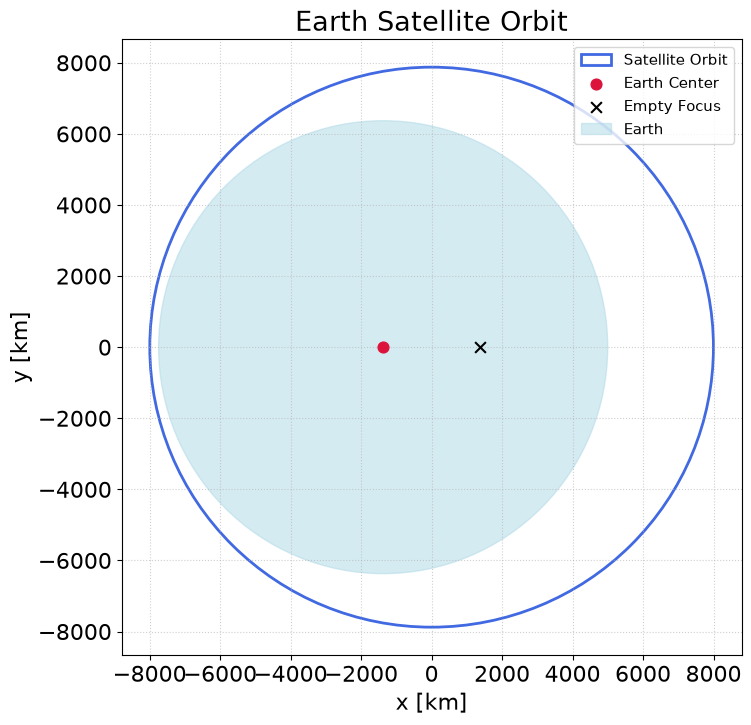

In [4]:
from matplotlib.patches import Ellipse, Circle

# Ellipse variables
a = (r_a + r_p) / 2.0
b = a * np.sqrt(1.0 - e**2)
c = a * e

fig, ax = plt.subplots(figsize=(8, 8))

# Orbit centered at (0, 0)
orbit = Ellipse(xy=(0, 0), width=2 * a, height=2 * b, angle=0, edgecolor='royalblue', facecolor='none', lw=2, label='Satellite Orbit')
ax.add_patch(orbit)

# Foci at (-c, 0) and (+c, 0)
ax.scatter([-c], [0], color='crimson', s=60, zorder=5, label='Earth Center')
ax.scatter([c], [0], color='black', marker='x', s=60, zorder=5, label='Empty Focus')

# Earth centered at Focus 1
earth = Circle(xy=(-c, 0), radius=R_earth, color='lightblue', alpha=0.5, label='Earth')
ax.add_patch(earth)

ax.set_xlabel('x [km]')
ax.set_ylabel('y [km]')
ax.set_title('Earth Satellite Orbit')
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(loc='upper right', fontsize='x-small')

plt.show()

#### 2. Planet hunting

One way to discover extrasolar planets is to monitor the line-of-sight velocity (called radial velocity or RV) of a nearby star. A periodic signal in the RV could indicate that the star has a planet. In order to model the planet's orbit, the astronomers have to be able to solve Kepler's equation: 

#### $M = E - e \sin E$ 

where $M$ is the mean anomaly, $E$ is the eccentric anomaly, and $e$ is the eccentricity. Since Kepler's equation is transcendental, it has no analytical solution and must be solved numerically.

#### 3. The true anomaly $f(t)$ (where $t$ is time) is the angle between ellipse's major axis and the vector connecting the star to the planet. In a markdown cell, describe how $E(t)$ and $M(t)$ relate to $f(t)$.
---

Following the formulation in Perryman (2011, Section 2.1), three angular coordinates (anomalies) track the motion of a planet along its Keplerian orbit:
- **True Anomaly $f(t)$** (also denoted $\nu(t)$): The physical angle measured from pericentre to the position of the orbiting body. It is the angle used to characterise an observational orbit.
- **Eccentric Anomaly $E(t)$**: An auxiliary geometric angle measured from the centre of the ellipse, referencing the auxiliary circle circumscribing the orbit.
- **Mean Anomaly $M(t)$**: An angle related to a fictitious mean motion around the orbit, used when calculating the true anomaly. Over a complete orbit, the real planet does not move at a constant angular rate. An average angular rate is specified in terms of the mean motion as (Perryman Eq. 2.8):
    $$n \equiv \frac{2\pi}{P}$$
    where $P$ is the orbital period. The mean anomaly at time $t - t_p$ after pericentre passage is then defined as (Perryman Eq. 2.9):
    $$M(t) = \frac{2\pi}{P}(t - t_p) \equiv n(t - t_p)$$
    The relation between the mean anomaly $M(t)$ and the eccentric anomaly $E(t)$ is derived from orbital dynamics. This relation is Kepler's equation:
    $$M(t) = E(t) - e\sin E(t)$$

---
Following Perryman (2011), the position of an orbiting body at any observation time $t$ is obtained as following:
1. **Calculate the mean anomaly $M(t)$** at time $t$ from the uniform mean motion:
   $$M(t) = \frac{2\pi}{P}(t - t_p)$$
2. **Solve Kepler's equation for the eccentric anomaly $E(t)$**:
   $$M(t) = E(t) - e\sin E(t)$$
   Because this equation is transcendental, it must be solved numerically.
3. **Obtain the true anomaly $f(t)$** using the geometric identity relating $E(t)$ and $f(t)$:
   $$\tan\left(\frac{f(t)}{2}\right) = \sqrt{\frac{1 + e}{1 - e}} \tan\left(\frac{E(t)}{2}\right)$$
   (or equivalently, $\cos f(t) = \frac{\cos E(t) - e}{1 - e\cos E(t)}$).
Thus, $M(t)$ provides the uniform time-tracking angle, $E(t)$ acts as the intermediate geometric angle found by solving Kepler's equation, and $f(t)$ gives the actual physical direction of the planet from the star.

---








#### 4. The following cell contains code for solving Kepler's equation and computing the radial velocity as a function of time:

In [5]:
# To solve Kepler's equation, make a good starting guess for eccentric anomaly
def KeplerStart3(e, M):
    # Inputs: eccentricity, mean anomaly in RADIANS
    t34 = e**2
    t35 = e*t34
    t33 = np.cos(M)
    return M + (-0.5*t35 + e + (t34 + 1.5*t33*t35)*t33) * np.sin(M)

# 3rd-order method for improving the guess for eccentric anomaly
def eps3(e, M, x):
    # Inputs: eccentricity, mean anomaly in RADIANS, estimate for eccentric anomaly in RADIANS
    t1 = np.cos(x)
    t2 = -1 + e*t1
    t3 = np.sin(x)
    t4 = e*t3
    t5 = -x + t4 + M
    t6 = t5/(0.5*t5*t4/t2 + t2)
    return t5 / ((0.5*t3 - (1./6.)*t1*t6)*e*t6 + t2);

# Solve Kepler's equation (suggested tolerance is 1e-14; Ford (2009) suggests 1e-6 is 
# good enough)
def KeplerSolve(e, M, tol):
    # Inputs: eccentricity, mean anomaly in RADIANS, tolerance
    Mnorm = M % (2*np.pi)
    E0 = KeplerStart3(e, Mnorm)
    dE = tol + 1
    count = 0
    while (dE > tol):
        EE = E0 - eps3(e, Mnorm, E0)
        dE = np.abs(EE - E0)
        E0 = EE
        count += 1
        if (count == 100):
            print("Astounding! KeplerSolve failed to converge!")
            break
    return EE

# Compute RV
def rv(inpars, e, omega, M0, Msini):
    # Inputs: inpars is a DICTIONARY of {"Tobs": observation times in SECONDS 
    # shifted so tobs[0] = 0, "Period": period in SECONDS, "Mstar": star mass in KG}. 
    # (The dictionary structure is because we don't want the Keplergram algorithm 
    # to optimize period or Mstar.) 
    # Other inputs are eccentricity, argument of periastron in RADIANS, 
    # mean anomaly at t=0 in RADIANS, planet M sin i in KG, RV offset in M/S
    # tol = 1.0e-10 # tolerance for KeplerSolve
    tobs = inpars["Tobs"]    
    period = inpars["Period"]
    mstar = inpars["Mstar"]
    am = np.cbrt(constants.G * mstar * period**2. / (4.*np.pi**2.)) # semimajor axis in meters
    # Pre-compute factor needed to convert eccentric anomaly to mean anomaly
    efactor = np.sqrt((1.+e)/(1.-e))
    # Turn observation times into mean anomalies
    Mvec = 2.*np.pi*(tobs/period) + M0
    # Find the eccentric anomaly using KeplerSolve, then the true anomaly analytically
    ftrue = np.zeros_like(Mvec)
    for i in range(len(tobs)):
        EE = KeplerSolve(e, Mvec[i], 1.0e-10)
        ftrue[i] = 2. * np.arctan(efactor*np.tan(0.5*EE))
    # Finally, return the radial velocity
    return np.sqrt(constants.G / ((mstar+Msini)*am*(1.-e**2.))) * Msini * \
        (np.cos(omega + ftrue) + e*np.cos(omega))

#### 5. RV Curve
Choose any planet planet from the <a href="https://exoplanet.eu/catalog/">Exoplanet Encyclopaedia</a> that has estimates for the mass, period, and eccentricity ($e$). You do not need an estimate of the planet radius. Calculate and plot the star's radial velocity as a function of time for at least three planet orbits. Put the name of your planet somewhere on your plot. Put a link to the planet's Exoplanet Encyclopaedia page in a markdown cell below.

Hints:
<ul>
<li>Unless you want to hunt down the actual observation times from the published literature on your star, you will need to make a vector of synthetic "observation times" to put into the dictionary that is the first argument of <tt>rv()</tt>. You can start at $t = 0$ and use <tt>np.linspace()</tt> or <tt>np.arange()</tt> to get a time vector that covers three or more orbital periods.</li> 
<li><tt>rv()</tt> requires a value for $\omega$, the argument of periastron of the orbit. $\omega$ is not in the Exoplanet Encyclopaedia table, but you can find it if you click on the name of the planet in the leftmost column. Make sure to convert from degrees to radians.</li>
<li>The first argument to <tt>rv()</tt> is a dictionary that packages the observation times, orbital period, and star mass. Star masses are also not in the planet table, but you will find them in the detailed info that you get after clicking on the planet name.</li>
<li><tt>Msini</tt> is the planet mass multiplied with the sine of the orbit inclination. If your chosen planet has no entry under $i$ (inclination) in the Exoplanet Encyclopaedia table, the number in the Mass column is actually $M \sin i$, which is a minimum mass estimate. The true mass could be higher. Often $i$ is unknown, but sometimes it can be measured (i.e. from transits).</li>
<li>Be sure to convert all numbers that you get from the Exoplanet Encyclopaedia into mks units. $M_{\rm Jup}$ is the mass of Jupiter.</li>
</ul>

---

### Target Planet: 51 Pegasi b
For this exercise, I selected 51 Pegasi b. Discovered by Michel Mayor and Didier Queloz in 1995, it was the first confirmed exoplanet orbiting a Sun-like star. I work on Doppler detections in my own research, so I wanted to pick the planet that started the field.
- **Catalogue Link:** [Exoplanet Encyclopaedia: 51 Peg b](https://exoplanet.eu/catalog/51_peg_b/)
- **Host Star Mass ($M_\star$):** $1.03\, M_\odot$
- **Planet Minimum Mass ($M \sin i$):** $0.46\, M_{\rm Jup}$
- **Orbital Period ($P$):** $4.2308\text{ days}$
- **Eccentricity ($e$):** $0.0069$
- **Argument of Periastron ($\omega$):** $54.1^\circ$

In [6]:
M_jup = 1.898e27 # in kg
M_sun = 1.989e30 # in kg

# 51 Peg b parameters from Exoplanet Encyclopaedia
period_days = 4.2307966                     # Orbital period
period_sec = period_days * constants.day
e = 0.0069                                  # Eccentricity
omega_rad = np.radians(54.1)                # Argument of periastron
M0_rad = 0.0                                # Mean anomaly at t=0

Msini_kg = 0.46 * M_jup
Mstar_kg = 1.03 * M_sun

# Synthetic observation grid for 3 orbits
n_periods = 3.0
n_points = 1000
t_obs_sec = np.linspace(0.0, n_periods * period_sec, n_points)

# Dictionary for the rv() function
inpars = {
    "Tobs": t_obs_sec,
    "Period": period_sec,
    "Mstar": Mstar_kg
}

# Calculate RV curve
rv_curve = rv(inpars, e, omega_rad, M0_rad, Msini_kg)

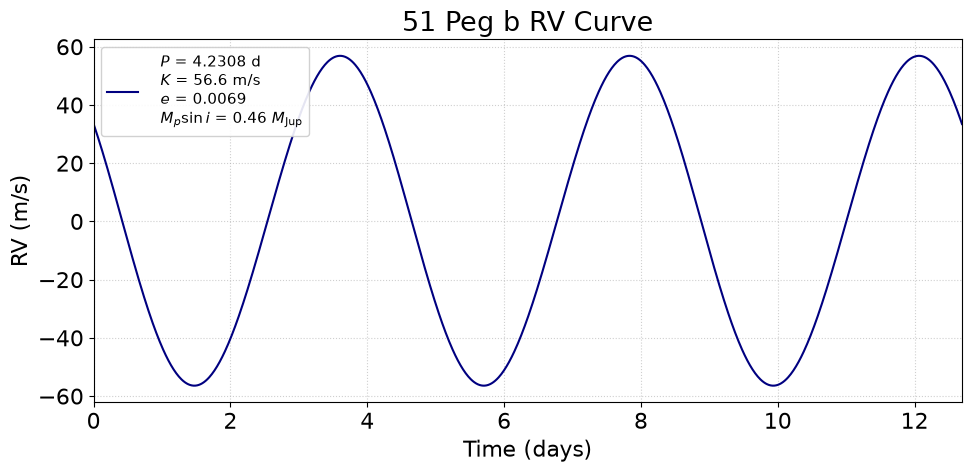

In [7]:
# Plot
fig, ax = plt.subplots(figsize=(10, 5))

t_obs_days = t_obs_sec / constants.day

# Planetary parameters for legend
planet_label = (
    rf"  $P$ = {period_days:.4f} d" "\n"
    rf"  $K$ = {np.ptp(rv_curve)/2:.1f} m/s" "\n"
    rf"  $e$ = {e:.4f}" "\n"
    rf"  $M_p \sin i$ = {Msini_kg / M_jup:.2f} $M_{{\rm Jup}}$"
)

ax.plot(t_obs_days, rv_curve, color='navy', label=planet_label)

ax.set_xlabel('Time (days)')
ax.set_ylabel('RV (m/s)')
ax.set_title('51 Peg b RV Curve')
ax.grid(True, linestyle=':', alpha=0.6)
ax.set_xlim(0, n_periods * period_days)
ax.legend(loc='upper left', fontsize='x-small', framealpha=0.9)

plt.tight_layout()
plt.show()

### Real Observations: Lick Observatory (Marcy et al. 1997)
I retrieved 111 radial velocity measurements of 51 Pegasi obtained with the Hamilton echelle spectrograph at Lick Observatory.


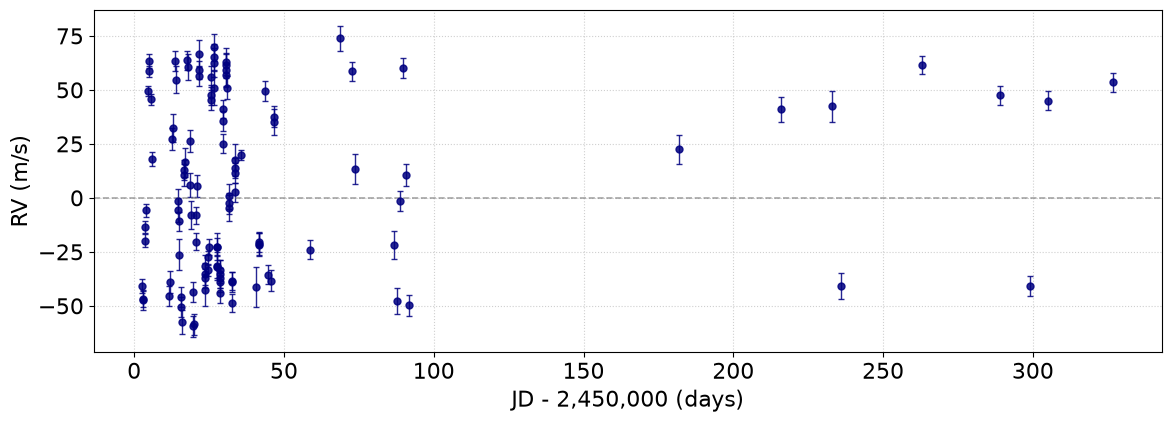

In [8]:
# Load observations (Marcy et al. 1997)
lick_data = np.genfromtxt('51_Pegasi_Lick_Marcy1997.csv', delimiter=',', skip_header=1)
jd_lick = lick_data[:, 0]
rv_lick = lick_data[:, 1]
err_lick = lick_data[:, 2]

# Time series plot
fig, ax = plt.subplots(figsize=(12, 4.5))

ax.errorbar(jd_lick - 2450000, rv_lick, yerr=err_lick, fmt='o',
            color='navy', ecolor='navy', markersize=5,
            elinewidth=1.0, capsize=2, alpha=0.85)

ax.axhline(0, color='gray', linestyle='--', lw=1.2, alpha=0.7)

ax.set_xlabel('JD - 2,450,000 (days)')
ax.set_ylabel('RV (m/s)')
ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

Treating the observations as an uncharacterized dataset, we compute the Lomb-Scargle periodogram in the frequency domain. We calculate False Alarm Probability (FAP) thresholds to identify significant periodic signals.

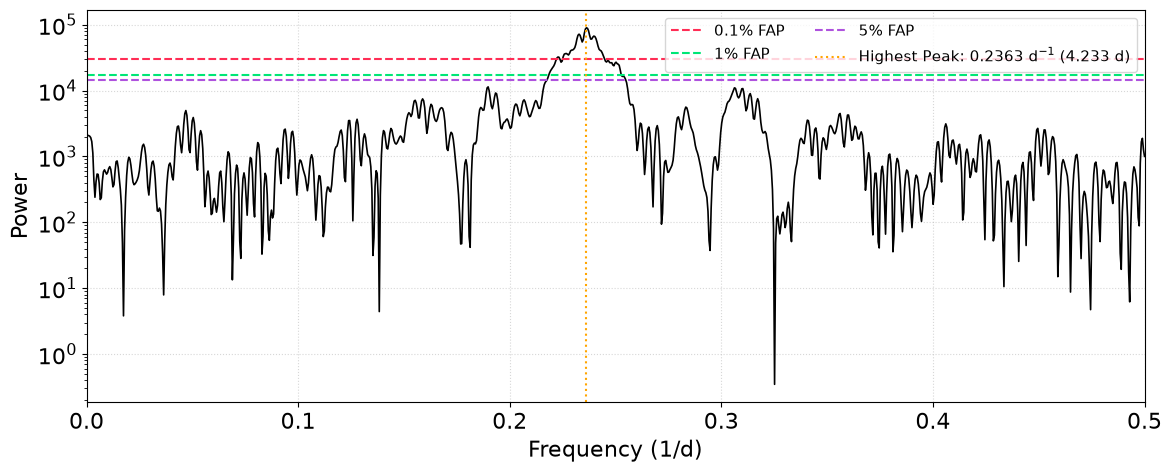

In [9]:
from astropy.timeseries import LombScargle

# Load measurements
lick_data = np.genfromtxt('51_Pegasi_Lick_Marcy1997.csv', delimiter=',', skip_header=1)
jd_lick = lick_data[:, 0]
rv_lick = lick_data[:, 1]
err_lick = lick_data[:, 2]

# Uniform frequency grid
freqs = np.linspace(0.001, 0.5, 1000)

# Compute periodogram and FAP thresholds
ls = LombScargle(jd_lick, rv_lick, normalization='psd')
power = ls.power(freqs)
faps = ls.false_alarm_level([0.001, 0.01, 0.05], method='bootstrap')

# Identify peak frequency and convert to period
peak_freq = freqs[np.argmax(power)]
peak_period = 1.0 / peak_freq

# Plot Periodogram in frequency domain
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(freqs, power, color='black', lw=1.2)
ax.set_ylabel('Power')
ax.set
ax.set_xlabel('Frequency (1/d)')
ax.set_xlim(0, 0.5)

# FAP threshold lines
ax.axhline(faps[0], ls='--', color='#FF2D55', lw=1.5, label='0.1% FAP')
ax.axhline(faps[1], ls='--', color='#00E676', lw=1.5, label='1% FAP')
ax.axhline(faps[2], ls='--', color='#AF52DE', lw=1.5, label='5% FAP')

# Peak frequency indicator
ax.axvline(peak_freq, color='orange', ls=':', lw=1.5,
           label=rf'Highest Peak: {peak_freq:.4f} d$^{{-1}}$ ({peak_period:.3f} d)')

ax.set_yscale('log')
ax.grid(True, which='major', linestyle=':', alpha=0.5)
ax.legend(loc='upper right', ncol=2, fontsize='x-small')


plt.tight_layout()
plt.show()

Or in the period domain:

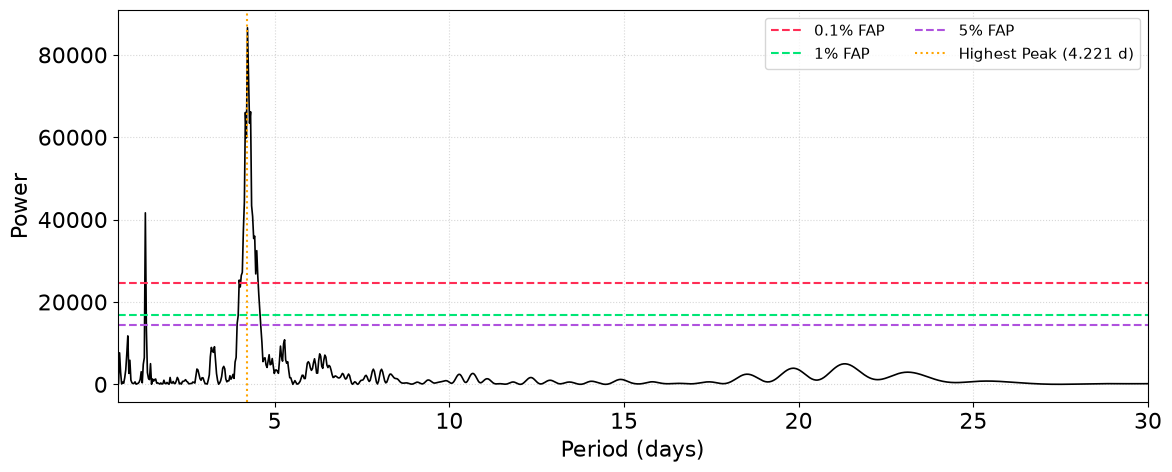

In [10]:
from astropy.timeseries import LombScargle

# Load measurements
lick_data = np.genfromtxt('51_Pegasi_Lick_Marcy1997.csv', delimiter=',', skip_header=1)
jd_lick = lick_data[:, 0]
rv_lick = lick_data[:, 1]
err_lick = lick_data[:, 2]

# Period grid for the search
periods = np.linspace(0.5, 30, 1000)
freqs = 1.0 / periods

# Compute periodogram and FAP thresholds
ls = LombScargle(jd_lick, rv_lick, normalization='psd')
power = ls.power(freqs)
faps = ls.false_alarm_level([0.001, 0.01, 0.05], method='bootstrap')

# Identify peak period
peak_period = periods[np.argmax(power)]

# Plot Periodogram
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(periods, power, color='black', lw=1.2)
ax.set_ylabel('Power')
ax.set_xlabel('Period (days)')
ax.set_xlim(0.5, 30)

# FAP threshold lines
ax.axhline(faps[0], ls='--', color='#FF2D55', lw=1.5, label='0.1% FAP')
ax.axhline(faps[1], ls='--', color='#00E676', lw=1.5, label='1% FAP')
ax.axhline(faps[2], ls='--', color='#AF52DE', lw=1.5, label='5% FAP')

# Peak period
ax.axvline(peak_period, color='orange', ls=':', lw=1.5,
           label=f'Highest Peak ({peak_period:.3f} d)')

ax.grid(True, which='major', linestyle=':', alpha=0.5)
ax.legend(loc='upper right', ncol=2, fontsize='x-small')

plt.tight_layout()
plt.show()

Keplerian orbits are typically modeled using Markov Chain Monte Carlo (MCMC) sampling. MCMC is preferred because it maps posterior parameter distributions, avoids unphysical negative eccentricities near $e \approx 0$, accounts for the $e$-$\omega$ degeneracy in circular orbits, and fits instrumental jitter. For the scope of this exercise, non-linear least-squares optimization (`scipy.optimize.curve_fit`) provides a simple determination of the best-fit parameters and parameter uncertainties without requiring an external MCMC sampler.

In [11]:
from scipy.optimize import curve_fit

# Keplerian RV model
def kepler_rv_model(t, P, K, e, omega, T0, gamma):
    # Mean anomaly
    M = 2.0 * np.pi * (t - T0) / P
    M = M % (2.0 * np.pi)
    
    # Solve Kepler's equation numerically (Newton-Raphson)
    E = M.copy()
    for _ in range(15):
        f = E - e * np.sin(E) - M
        f_prime = 1.0 - e * np.cos(E)
        E -= f / f_prime
        
    # True anomaly via half-angle formula
    nu = 2.0 * np.arctan(np.sqrt((1.0 + e) / (1.0 - e)) * np.tan(0.5 * E))
    
    # Radial velocity with zero-point offset gamma
    return gamma + K * (np.cos(omega + nu) + e * np.cos(omega))

# Initial guesses
P_guess = peak_period                                    
K_guess = (rv_lick.max() - rv_lick.min()) / 2.0          
e_guess = 0.01                                 
omega_guess = 0.0                             
T0_guess = jd_lick[0]                                 
gamma_guess = np.mean(rv_lick)                          

p0 = [P_guess, K_guess, e_guess, omega_guess, T0_guess, gamma_guess]

bounds = (
    [P_guess - 0.2, 5.0, 0.0, -np.pi, T0_guess - P_guess, gamma_guess - 30.0],
    [P_guess + 0.2, 100.0, 0.5,  np.pi, T0_guess + P_guess, gamma_guess + 30.0]
)

# Fit the model to the observations
popt, pcov = curve_fit(kepler_rv_model, jd_lick, rv_lick, p0=p0, sigma=err_lick, bounds=bounds)
P_fit, K_fit, e_fit, omega_fit, T0_fit, gamma_fit = popt
errors = np.sqrt(np.diag(pcov))

In [12]:
Mstar_kg = 1.03 * 1.989e30
P_sec = P_fit * constants.day

# Minimum mass
Msini_kg = K_fit * np.sqrt(1 - e_fit**2) * ((P_sec * Mstar_kg**2) / (2 * np.pi * constants.G))**(1/3)
Msini_jup = Msini_kg / 1.898e27

# Uncertainty propagation to minimum mass (errors[1] is sigma_K, errors[0] is sigma_P)
rel_err_Msini = np.sqrt((errors[1] / K_fit)**2 + (errors[0] / (3.0 * P_fit))**2)
err_Msini_jup = Msini_jup * rel_err_Msini

# Planetary parameters
print(f"P (d): {P_fit:.5f} +/- {errors[0]:.5f}")
print(f"K (m/s): {K_fit:.2f} +/- {errors[1]:.2f}")
print(f"e: {e_fit:.4f} +/- {errors[2]:.4f}")
print(f"omega (deg): {np.degrees(omega_fit):.1f} +/- {np.degrees(errors[3]):.1f}")
print(f"Mp sin i (M_J): {Msini_jup:.3f} +/- {err_Msini_jup:.3f}")

P (d): 4.23060 +/- 0.00062
K (m/s): 56.05 +/- 1.36
e: 0.0151 +/- 0.0117
omega (deg): 30.3 +/- 41.3
Mp sin i (M_J): 0.455 +/- 0.011


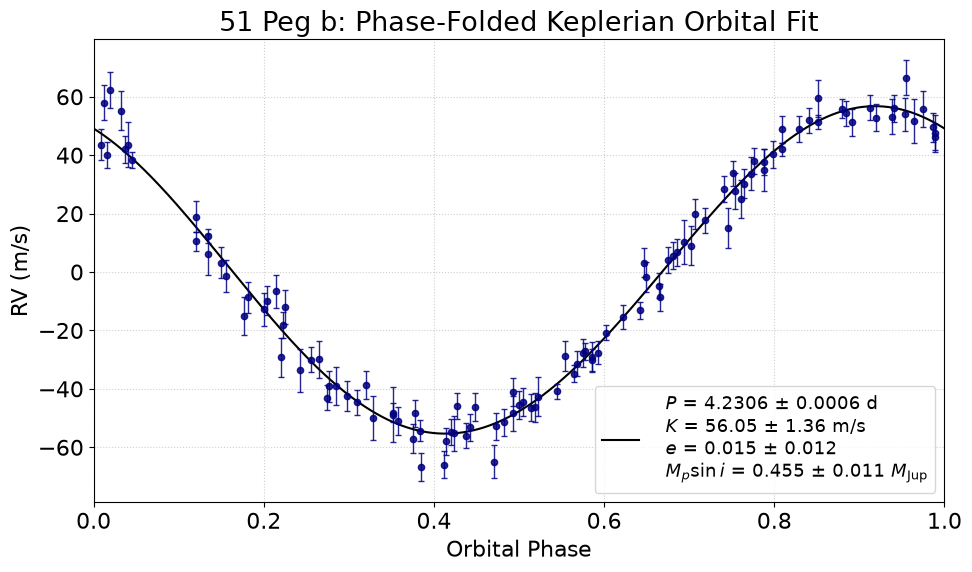

In [13]:
# Orbital phase
phase_obs = ((jd_lick - T0_fit) % P_fit) / P_fit
rv_detrended = rv_lick - gamma_fit

# Best-fit model curve
phase_grid = np.linspace(0.0, 1.0, 500)
t_model = T0_fit + phase_grid * P_fit
model_curve = kepler_rv_model(t_model, P_fit, K_fit, e_fit, omega_fit, T0_fit, gamma_fit) - gamma_fit

# Planetary parameters
fit_label = (
    rf"  $P$ = {P_fit:.4f} $\pm$ {errors[0]:.4f} d" "\n"
    rf"  $K$ = {K_fit:.2f} $\pm$ {errors[1]:.2f} m/s" "\n"
    rf"  $e$ = {e_fit:.3f} $\pm$ {errors[2]:.3f}" "\n"
    rf"  $M_p \sin i$ = {Msini_jup:.3f} $\pm$ {err_Msini_jup:.3f} $M_{{\rm Jup}}$")

# Plot
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(phase_grid, model_curve, color='black', label=fit_label)
ax.errorbar(phase_obs, rv_detrended, yerr=err_lick, fmt='o',
            color='navy', markersize=4.5, alpha=0.85, 
            elinewidth=1.0, capsize=2)

ax.set_xlabel('Orbital Phase')
ax.set_ylabel('RV (m/s)')
ax.set_title('51 Peg b: Phase-Folded Keplerian Orbital Fit')
ax.set_xlim(0, 1)
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(loc='lower right', fontsize='small')

plt.tight_layout()
plt.show()

### References
1. Perryman, M. (2011). *The Exoplanet Handbook*. Cambridge University Press, Chapter 2: Radial velocities (pp. 9-11).  
2. Mayor, M., & Queloz, D. (1995). A Jupiter-mass companion to a solar-type star. *Nature* 378, 355–359.  
3. Marcy, G. W. et al. (1997). The Planet around 51 Pegasi. *The Astrophysical Journal*, 481(2), 926–935.  
